## Time Series Grid SANOS Market Generation Test: State 10

This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [1]:

import os
os.environ["JAX_ENABLE_X64"] = "True"

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos
%aimport quantdata.dysanos.grid.interpolated
%aimport quantdata.dysanos.grid.torch_load
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 

from quantdata.dysanos.grid.torch_load import load, date, preprocess
r_nms = load("nms", start=date(2020,1,1), num_workers=8, grid_num_strikes=100)
print(f"nms /done - found {len(r_nms.ts['dates'])} dates.")
    

00: Generating interpolated time series for SPX for 1413 dates from 2020-01-02 to 2025-08-29 on nms grid:
01:   Day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Market Arb free settings: surface,mhs=0.0001,mw=0.10,mav=0.05,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Grid config: nms,rg=(-2,1),nm=100,xp=(2.0,4.9,9.9,39.5,126.0,252.0);sth=0.25,mid=0.01,mxd=2
00: Loading marker data for SPX for 1413 dates from 2020-01-02 to 2025-08-29 on NMS grid with 8p pool:
01:   Fitting SPX date 784/1413 2023-02-16: done; so far this took 5s...

/home/hans/vqdata/lib/python3.12/site-packages/cdxcore/bs.py:911: UserWarning: Found 1 of 113 prices below intrinsic value; worst undershoot is -2.749e-08. Violations: price[0] 0.4392540776033517 < intrinsic[0] 0.43925410509109497. [tolerance 1.0000e-08]
/home/hans/vqdata/lib/python3.12/site-packages/cdxcore/bs.py:911: UserWarning: Found 1 of 115 prices below intrinsic value; worst undershoot is -2.708e-08. Violations: price[0] 0.43932006035374116 < intrinsic[0] 0.43932008743286133. [tolerance 1.0000e-08]
/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/sanos/sanos_tools.py:457: UserWarning: Surface fit: Solver error: Solver 'HIGHS' failed. Try another solver, or solve with verbose=True for more information.. Attempting to solve with fallback solver.
/home/hans/vqdata/lib/python3.12/site-packages/cdxcore/bs.py:911: UserWarning: Found 1 of 88 prices below intrinsic value; worst undershoot is -4.625e-08. Violations: price[0] 0.4655189051615235 < intrinsic[0] 0.4655189514160156. [t

01:   Fitting SPX date 800/1413 2023-03-13: done; so far this took 4:10...

/home/hans/vqdata/lib/python3.12/site-packages/cdxcore/bs.py:911: UserWarning: Found 1 of 169 prices below intrinsic value; worst undershoot is -2.722e-08. Violations: price[0] 0.5661823179352212 < intrinsic[0] 0.5661823451519012. [tolerance 1.0000e-08]


01:   Fitting SPX date 832/1413 2023-04-04: done; so far this took 6:12...

/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/sanos/sanos_tools.py:457: UserWarning: Surface fit: Solver error: Solver 'HIGHS' failed. Try another solver, or solve with verbose=True for more information.. Attempting to solve with fallback solver.


... (59 outputs left out)

/home/hans/vqdata/lib/python3.12/site-packages/cdxcore/bs.py:911: UserWarning: Found 2 of 103 prices below intrinsic value; worst undershoot is -1.612e-08. Violations: price[0] 0.6054316015291652 < intrinsic[0] 0.6054316163063049, price[1] 0.5695617335762151 < intrinsic[1] 0.5695617496967316. [tolerance 1.0000e-08]


01:   Fitting SPX date 1347/1413 2025-05-27: done; so far this took 50:23...

/home/hans/vqdata/lib/python3.12/site-packages/cdxcore/bs.py:911: UserWarning: Found 1 of 157 prices below intrinsic value; worst undershoot is -4.386e-08. Violations: price[0] 0.6274371304610094 < intrinsic[0] 0.627437174320221. [tolerance 1.0000e-08]
/home/hans/vqdata/lib/python3.12/site-packages/cdxcore/bs.py:911: UserWarning: Found 2 of 403 prices below intrinsic value; worst undershoot is -4.386e-08. Violations: price[0] 0.7967927911379658 < intrinsic[0] 0.7967928349971771, price[1] 0.6274534919360005 < intrinsic[1] 0.6274535357952118. [tolerance 1.0000e-08]


00: Loaded market data for SPX for 1413/1413 dates from 2020-01-02 to 2025-08-29 on NMS grid with 8p pool; this took 57:28.
00: Fitted SPX for 1412 dates from 2020-01-02 to 2025-08-29 on NMS grid; this took 57:28.
nms /done - found 1412 dates.


00: Training 20-fixed-selu-nk100 version 0.3 for 100000 epochs on SPX for date range 2020-01-01_2025-08-30x
00: Using all samples with learning rate 0.001 and weight decay 0.0001.
01:   Model config: 0.10-smooth@20 midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=100,a=SELU,b=True)
01:   Grid config: nms,rg=(-2,1),nm=100,xp=(2.0,4.9,9.9,39.5,126.0,252.0);sth=0.25,mid=0.01,mxd=2
01:   Mk Arb Free pre-processor: surface,mhs=0.0001,mw=0.10,mav=0.05,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Raw day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
00: Preparing data set 20-fixed-selu-nk100 version 0.3 for 0.10-smooth@20 midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=100,a=SELU,b=True) traing TrainConfig(num_epochs=100000, lr=0.001, weight_decay=0.0001, batch_size=None) on Env(prec=32,device=cuda,debug=False)... done; this took 5s.
00: Instantiating 20-fix

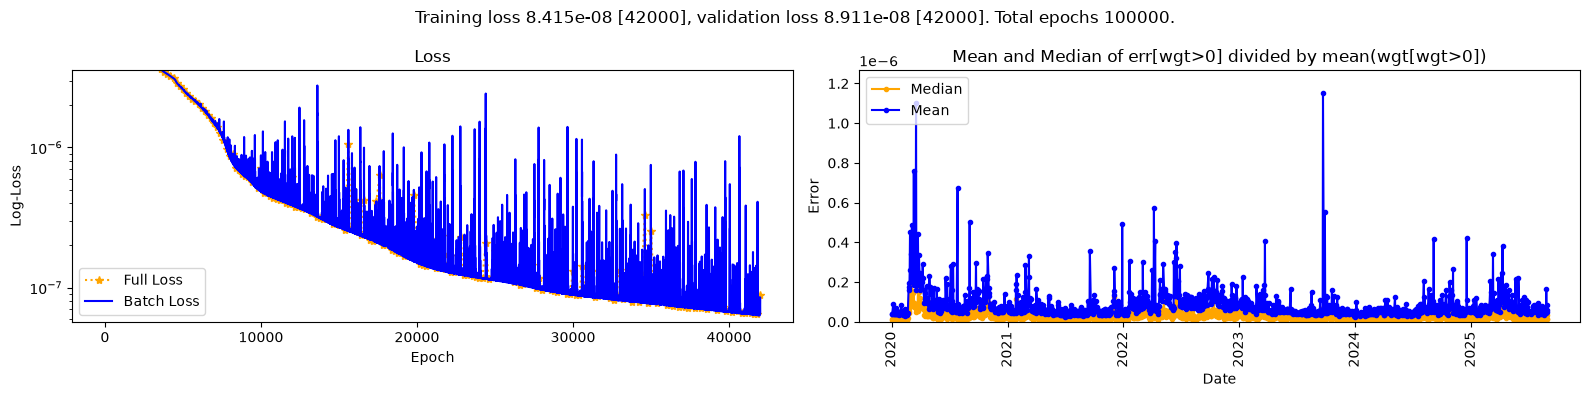

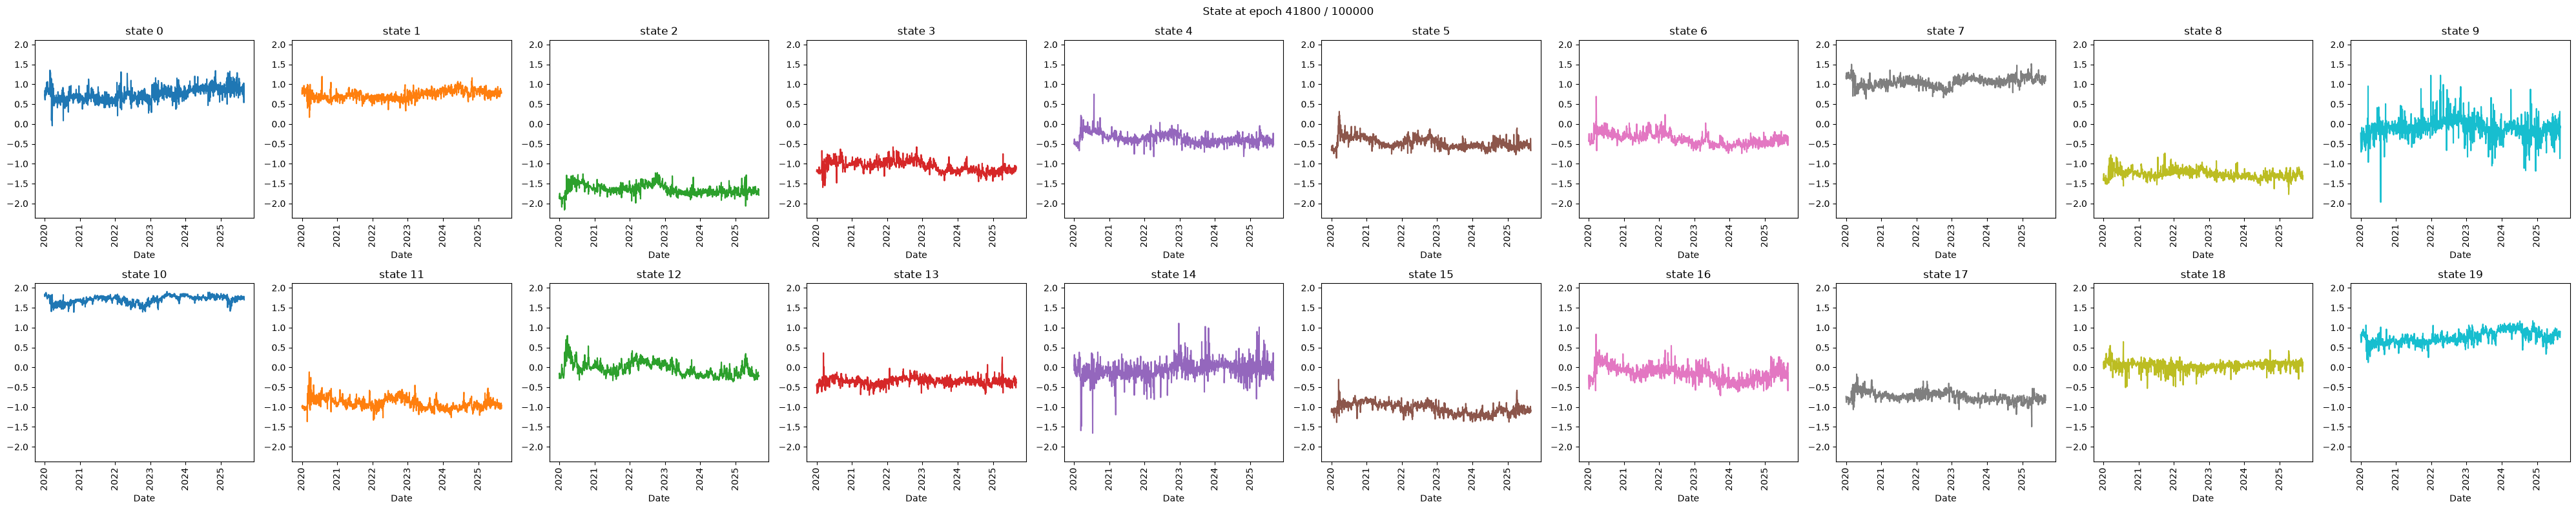

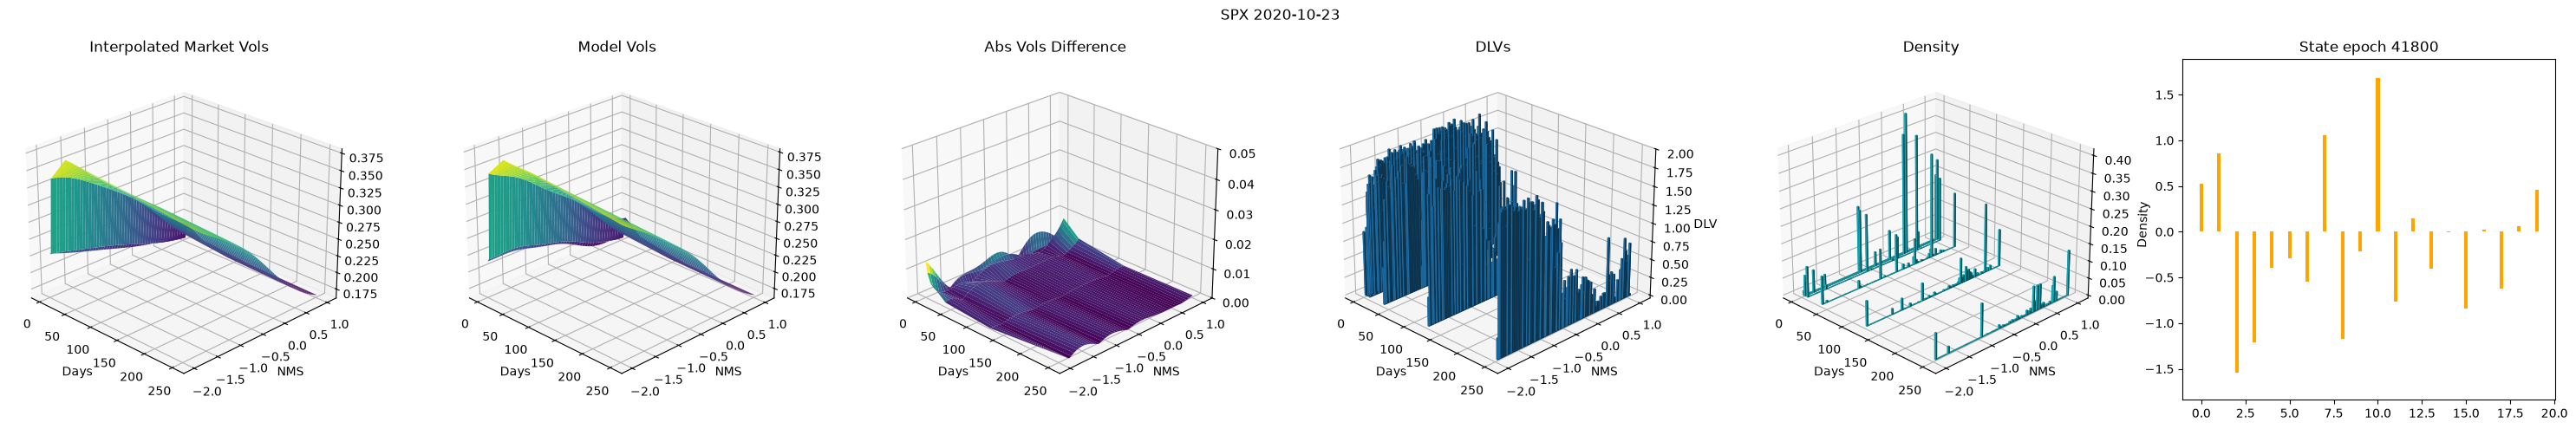

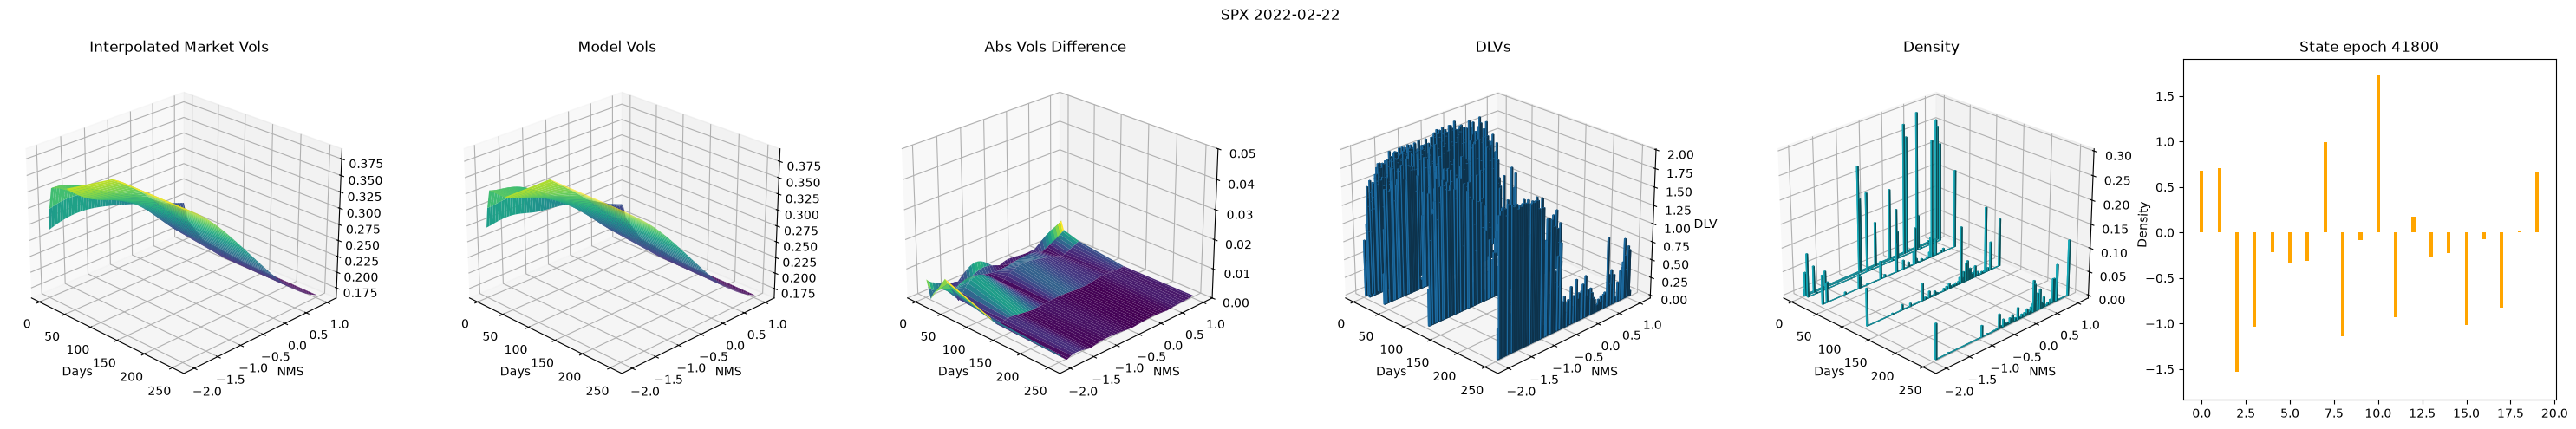

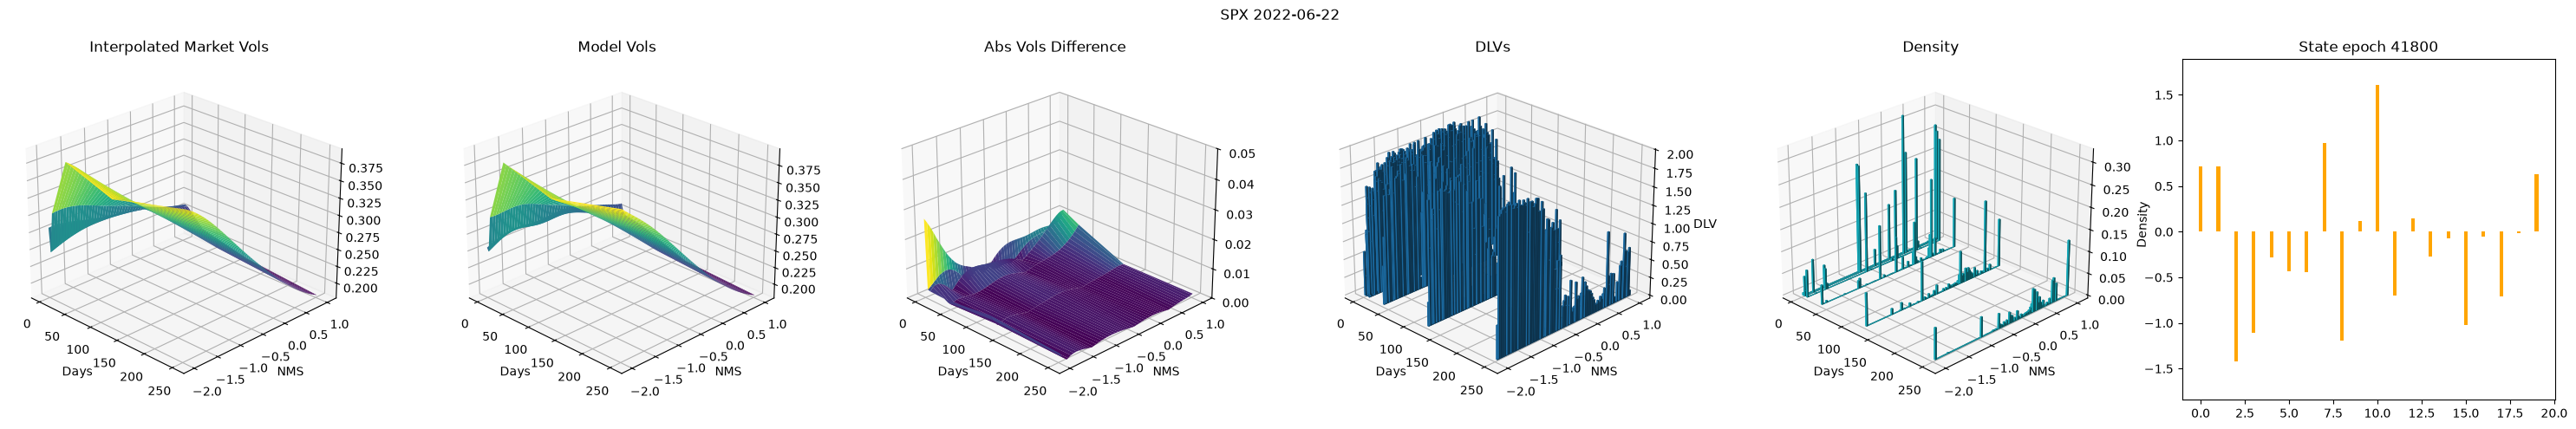

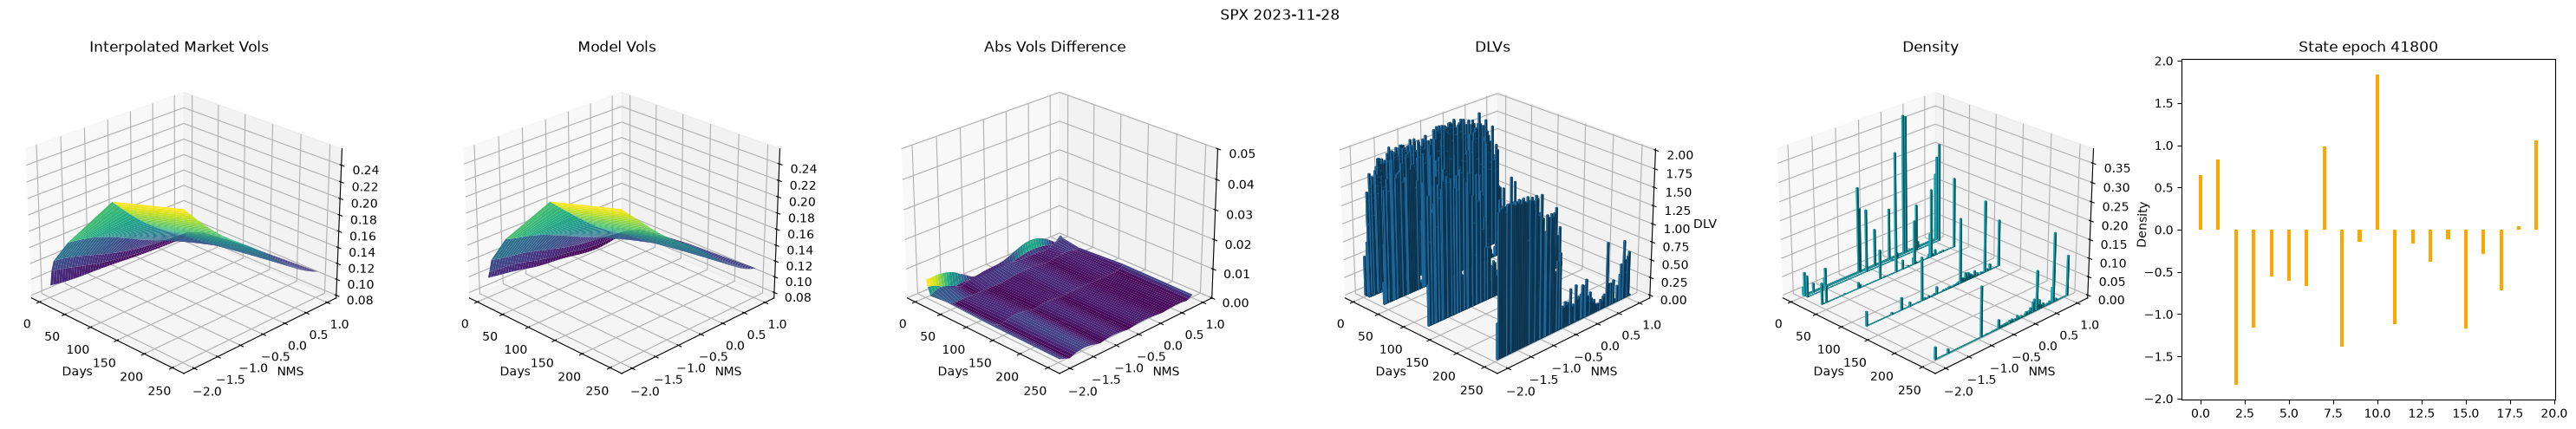

00: Training 0.10-smooth@20 midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=100,a=SELU,b=True) with TrainConfig(num_epochs=100000, lr=0.001, weight_decay=0.0001, batch_size=None) on Env(prec=32,device=cuda,debug=False):
01:   Epoch 1/100000, Loss: 0.06164. So far this took 0.38s.

/home/hans/vqdata/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


01:   Epoch 42000/100000, Loss: 8.415e-08. So far this took 2:54:54.                                               

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [2]:
from cdxcore.bs import bs
from flax.nnx import state

from quantdata.biz_calendar import DAYS_PER_YEAR
from quantdata.dysanos.grid.torch_model import BaseEnvironment, SanosCompressorConfig, SanosCompressor, FeedForward, torch
from dataclasses import dataclass
import numpy as np
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m
from quantdata.dysanos.grid.torch_gfx import Display
from quantdata.dysanos.grid.torch_train import train, TrainConfig

mdl_config = SanosCompressorConfig( 
    label="20-fixed-selu-nk100",
    user_version="0.3",
    smoothness = 0.1,
    num_state = 20, 
    state_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
    learn_config = None
)

trn_config = TrainConfig( num_epochs=100000, lr=1E-3, weight_decay=1e-4 )
r = train( r_nms, mdl_config=mdl_config, trn_config=trn_config, num_viz_dates=4  )
print("/done")
